# ABC-8 · VIN Group (giả định) — chạy từng bước

Mở file này ở thư mục project, chọn kernel của **venv** (`.venv`), rồi chạy từ trên xuống.
Các bảng và biểu đồ đã có sẵn kết quả để bạn xem ngay mà không cần chạy lại.

Trên **Google Colab**: bỏ dấu `#` ở dòng `git clone` trong ô đầu tiên (đổi link GitHub của bạn).

## 0. Chuẩn bị

In [1]:
import os, sys
# Trên Colab: bỏ dấu # để clone project từ GitHub (đổi link của bạn)
# !git clone https://github.com/<ten-tai-khoan>/<ten-repo>.git /content/stock-simulator
if os.path.isdir("/content/stock-simulator"):
    os.chdir("/content/stock-simulator")
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Image, Video
import data_service as ds, charts

pd.options.display.float_format = '{:,.2f}'.format
CSV_PATH = "data/abc-8.csv"
os.makedirs("output", exist_ok=True)

## 1. Dữ liệu và bảng thống kê

In [2]:
df = ds.load_prices(CSV_PATH)
print(f"Đã đọc {len(df)} ngày, từ {df['date'].min():%d/%m/%Y} đến {df['date'].max():%d/%m/%Y}")
df[['date', 'open', 'high', 'low', 'close', 'ref', 'floor', 'ceil', 'ret']].head(10)

Đã đọc 365 ngày, từ 01/01/2025 đến 31/12/2025


,date,open,high,low,close,ref,floor,ceil,ret
0,2025-01-01,"9,000.00","11,000.00","9,000.00","9,173.81","10,000.00","9,000.00","11,000.00",-8.26
1,2025-01-02,"10,091.19","10,091.19","8,256.43","10,091.19","9,173.81","8,256.43","10,091.19",10.00
2,2025-01-03,"11,100.31","11,100.31","9,082.07","11,100.31","10,091.19","9,082.07","11,100.31",10.00
3,2025-01-04,"9,990.28","12,210.34","9,990.28","11,240.19","11,100.31","9,990.28","12,210.34",1.26
4,2025-01-05,"12,364.21","12,364.21","10,116.17","11,393.03","11,240.19","10,116.17","12,364.21",1.36
5,2025-01-06,"10,253.73","12,532.33","10,253.73","10,253.73","11,393.03","10,253.73","12,532.33",-10.00
6,2025-01-07,"10,861.40","11,279.10","9,228.35","11,279.10","10,253.73","9,228.35","11,279.10",10.00
7,2025-01-08,"10,151.19","12,258.00","10,151.19","10,151.19","11,279.10","10,151.19","12,407.01",-10.00
8,2025-01-09,"11,166.31","11,166.31","9,136.07","9,136.07","10,151.19","9,136.07","11,166.31",-10.00
9,2025-01-10,"8,222.46","10,049.68","8,222.46","8,222.46","9,136.07","8,222.46","10,049.68",-10.00


In [3]:
display(ds.monthly_stats(df))
display(ds.quarter_stats(df))

,Trung bình,Trung vị,Độ lệch chuẩn,Thấp nhất,Cao nhất,Biên độ,Biên độ / TB (%),Hệ số biến thiên (%)
Tháng,,,,,,,,
1,"11,397.77","10,698.83","2,934.79","6,857.03","19,096.36","12,239.33",107.38,25.75
2,"16,828.83","17,138.84","4,648.17","9,230.00","27,974.06","18,744.07",111.38,27.62
3,"20,479.23","20,031.62","2,976.59","15,124.82","29,531.22","14,406.40",70.35,14.53
4,"27,493.45","27,198.61","6,105.20","16,502.97","41,360.29","24,857.32",90.41,22.21
5,"39,934.81","39,632.63","5,444.40","27,015.35","55,423.49","28,408.14",71.14,13.63
6,"36,606.98","35,463.69","10,597.25","20,683.31","61,296.52","40,613.21",110.94,28.95
7,"30,243.39","30,030.30","4,093.02","22,131.22","40,402.80","18,271.58",60.42,13.53
8,"25,989.07","25,381.68","3,808.06","18,995.49","34,468.95","15,473.46",59.54,14.65
9,"39,864.42","38,269.09","7,407.64","27,212.95","57,509.80","30,296.85",76.00,18.58


,Trung bình,Trung vị,Độ lệch chuẩn,Thấp nhất,Cao nhất,Biên độ,Biên độ / TB (%),Hệ số biến thiên (%),Biến động ngày (%)
Quý,,,,,,,,,
1,"16,215.49","16,781.82","5,205.26","6,857.03","29,531.22","22,674.19",139.83,32.10,8.60
2,"34,736.18","34,712.00","9,322.94","16,502.97","61,296.52","44,793.55",128.95,26.84,8.64
3,"31,947.16","30,421.02","7,859.18","18,995.49","57,509.80","38,514.31",120.56,24.60,8.62
4,"38,260.82","35,011.33","10,896.48","20,421.55","73,849.19","53,427.64",139.64,28.48,8.93


## 2. Biểu đồ phân tích

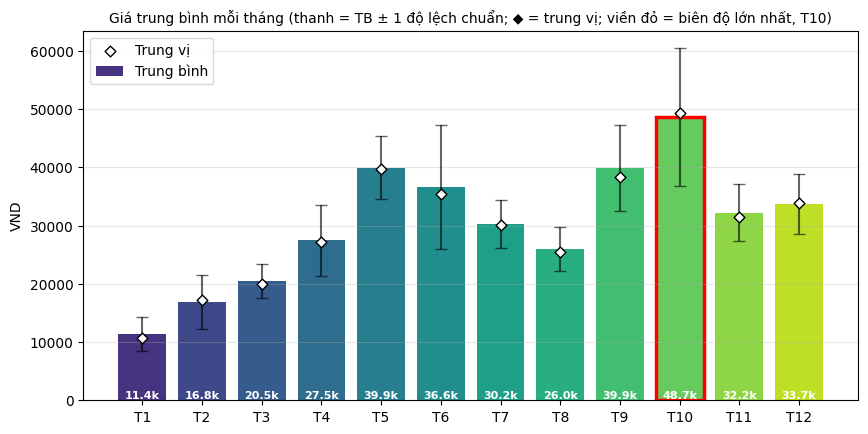

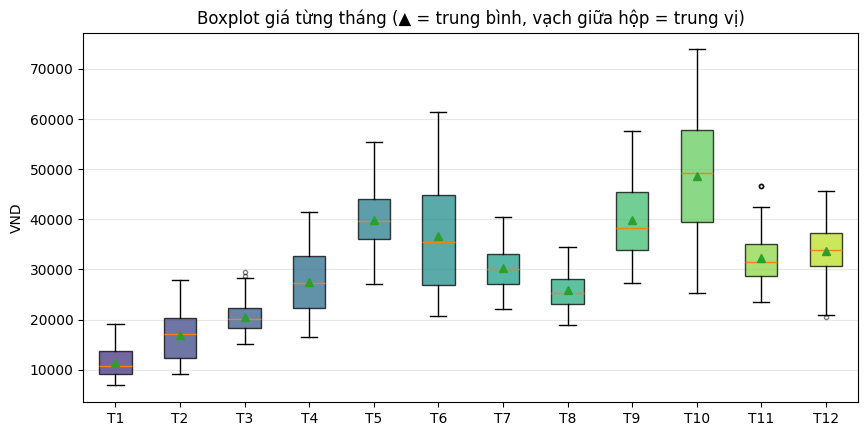

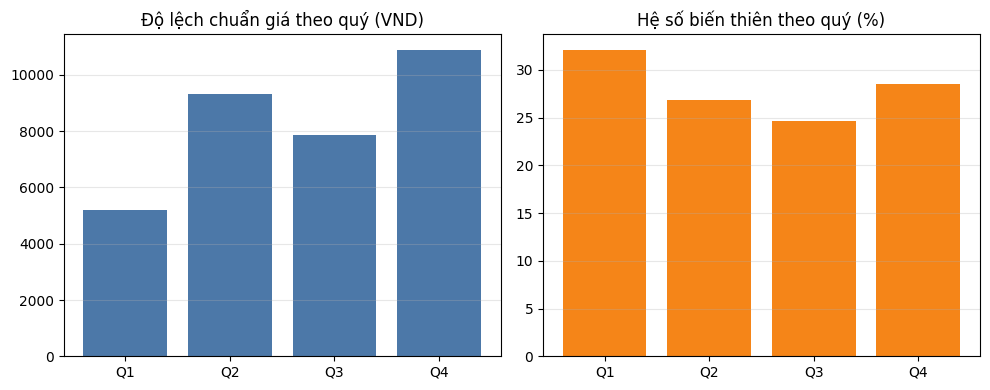

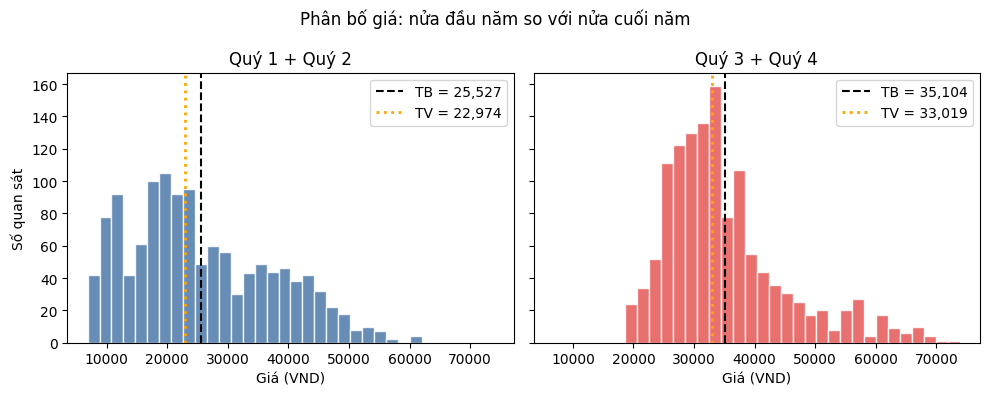

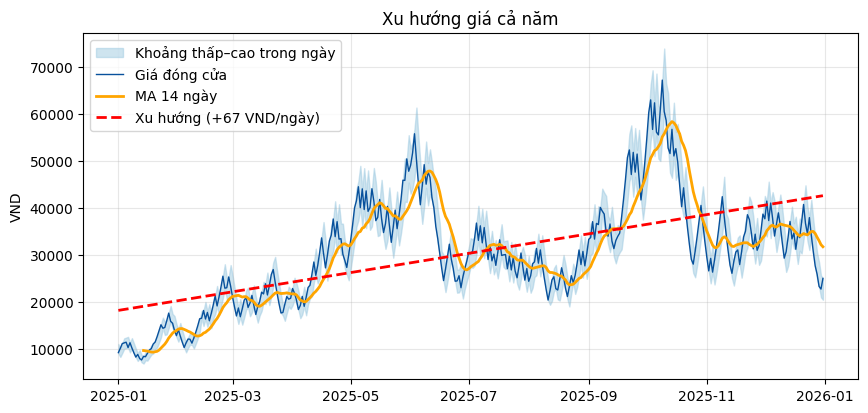

In [4]:
for f in (charts.fig_monthly_mean, charts.fig_boxplot, charts.fig_quarters,
          charts.fig_hist_halves, charts.fig_trend):
    f(df); plt.show()

## 3. Ngày bất thường và kết luận

,Ngày,Tham chiếu,Sàn,Trần,Đóng cửa,Đóng cửa ở,Số lần sàn,Số lần trần,Số lần = TC,Ghi chú
0,2025-01-03,"10,091.19","9,082.07","11,100.31","11,100.31",ceil,1,5,0,chạm sàn 1 lần; chạm trần 5 lần
1,2025-01-06,"11,393.03","10,253.73","12,532.33","10,253.73",floor,5,1,0,chạm sàn 5 lần; chạm trần 1 lần
2,2025-01-08,"11,279.10","10,151.19","12,407.01","10,151.19",floor,6,0,0,chạm sàn 6 lần
3,2025-01-10,"9,136.07","8,222.46","10,049.68","8,222.46",floor,4,2,0,chạm sàn 4 lần; chạm trần 2 lần
4,2025-01-16,"8,308.58","7,477.72","9,139.44","9,038.04",up,3,3,0,chạm sàn 3 lần; chạm trần 3 lần
5,2025-02-02,"14,067.97","12,661.17","15,474.77","12,661.17",floor,2,4,0,chạm sàn 2 lần; chạm trần 4 lần
6,2025-02-03,"12,661.17","11,395.06","13,927.29","11,395.06",floor,4,2,0,chạm sàn 4 lần; chạm trần 2 lần
7,2025-02-12,"14,889.50","13,400.55","16,378.45","16,378.45",ceil,1,5,0,chạm sàn 1 lần; chạm trần 5 lần
8,2025-02-18,"15,950.13","14,355.12","17,545.14","17,545.14",ceil,3,3,0,chạm sàn 3 lần; chạm trần 3 lần
9,2025-02-20,"19,299.66","17,369.69","21,229.62","21,229.62",ceil,3,3,0,chạm sàn 3 lần; chạm trần 3 lần


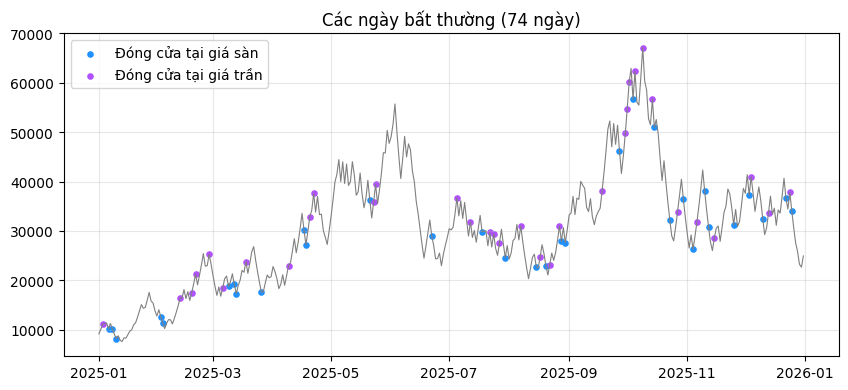

In [5]:
anom = ds.find_anomalies(df)
display(anom)
charts.fig_anomalies(df, anom); plt.show()

In [6]:
info = ds.build_insights(df)
print("KẾT LUẬN")
for i, t in enumerate(info["conclusions"], 1):
    print(f"{i}. {t}")

KẾT LUẬN
1. Xu hướng: đường xu hướng TĂNG, độ dốc +67 VND mỗi ngày. Giá đóng cửa ngày cuối năm so với ngày đầu năm thay đổi +177.33%.
2. Trung bình và trung vị cả năm: 30,355 VND và 29,989 VND; trung bình cao hơn trung vị, nghĩa là một số ngày giá cao đã kéo trung bình lên.
3. Theo tháng: T10 có giá trung bình cao nhất (48,656 VND), T1 thấp nhất (11,398 VND). T10 có biên độ lớn nhất (48,651 VND), đây là tháng dao động mạnh nhất.
4. Theo quý: Q4 có độ lệch chuẩn lớn nhất (10,896 VND), Q1 nhỏ nhất (5,205 VND). Độ lệch chuẩn càng lớn thì giá càng phân tán.
5. Ngày bất thường: 74 ngày có giá chạm sàn/trần từ 6 phiên trở lên, hoặc có phiên bằng giá tham chiếu, hoặc vượt khung sàn–trần. Trong đó 0 ngày kịch sàn hoặc kịch trần cả ngày.
6. Đỉnh giá 73,849 VND vào ngày 10/10/2025; đáy giá 6,857 VND vào ngày 14/01/2025.
7. Biên độ dao động lớn nhất trong một ngày là 13,427 VND, xảy ra vào ngày 10/10/2025.
8. Vì sao đường đi xuống nhưng màu xanh: màu của mỗi đoạn không phụ thuộc hướng lên hay xuố

## 4. Biểu đồ nến cả năm (mỗi nến gom 3 ngày)

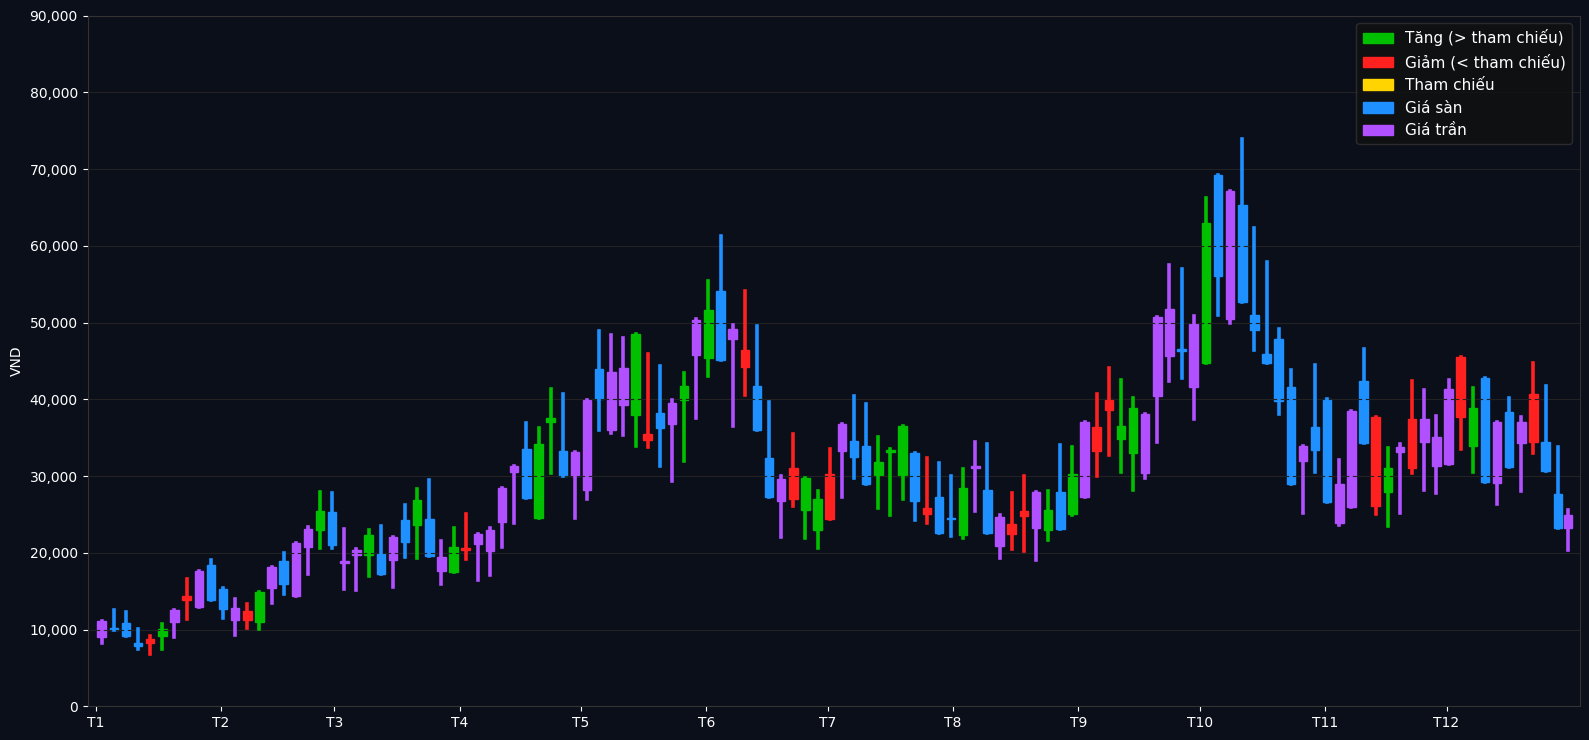

In [7]:
charts.fig_candles(df); plt.show()

## 5. Xem trước khung hình video

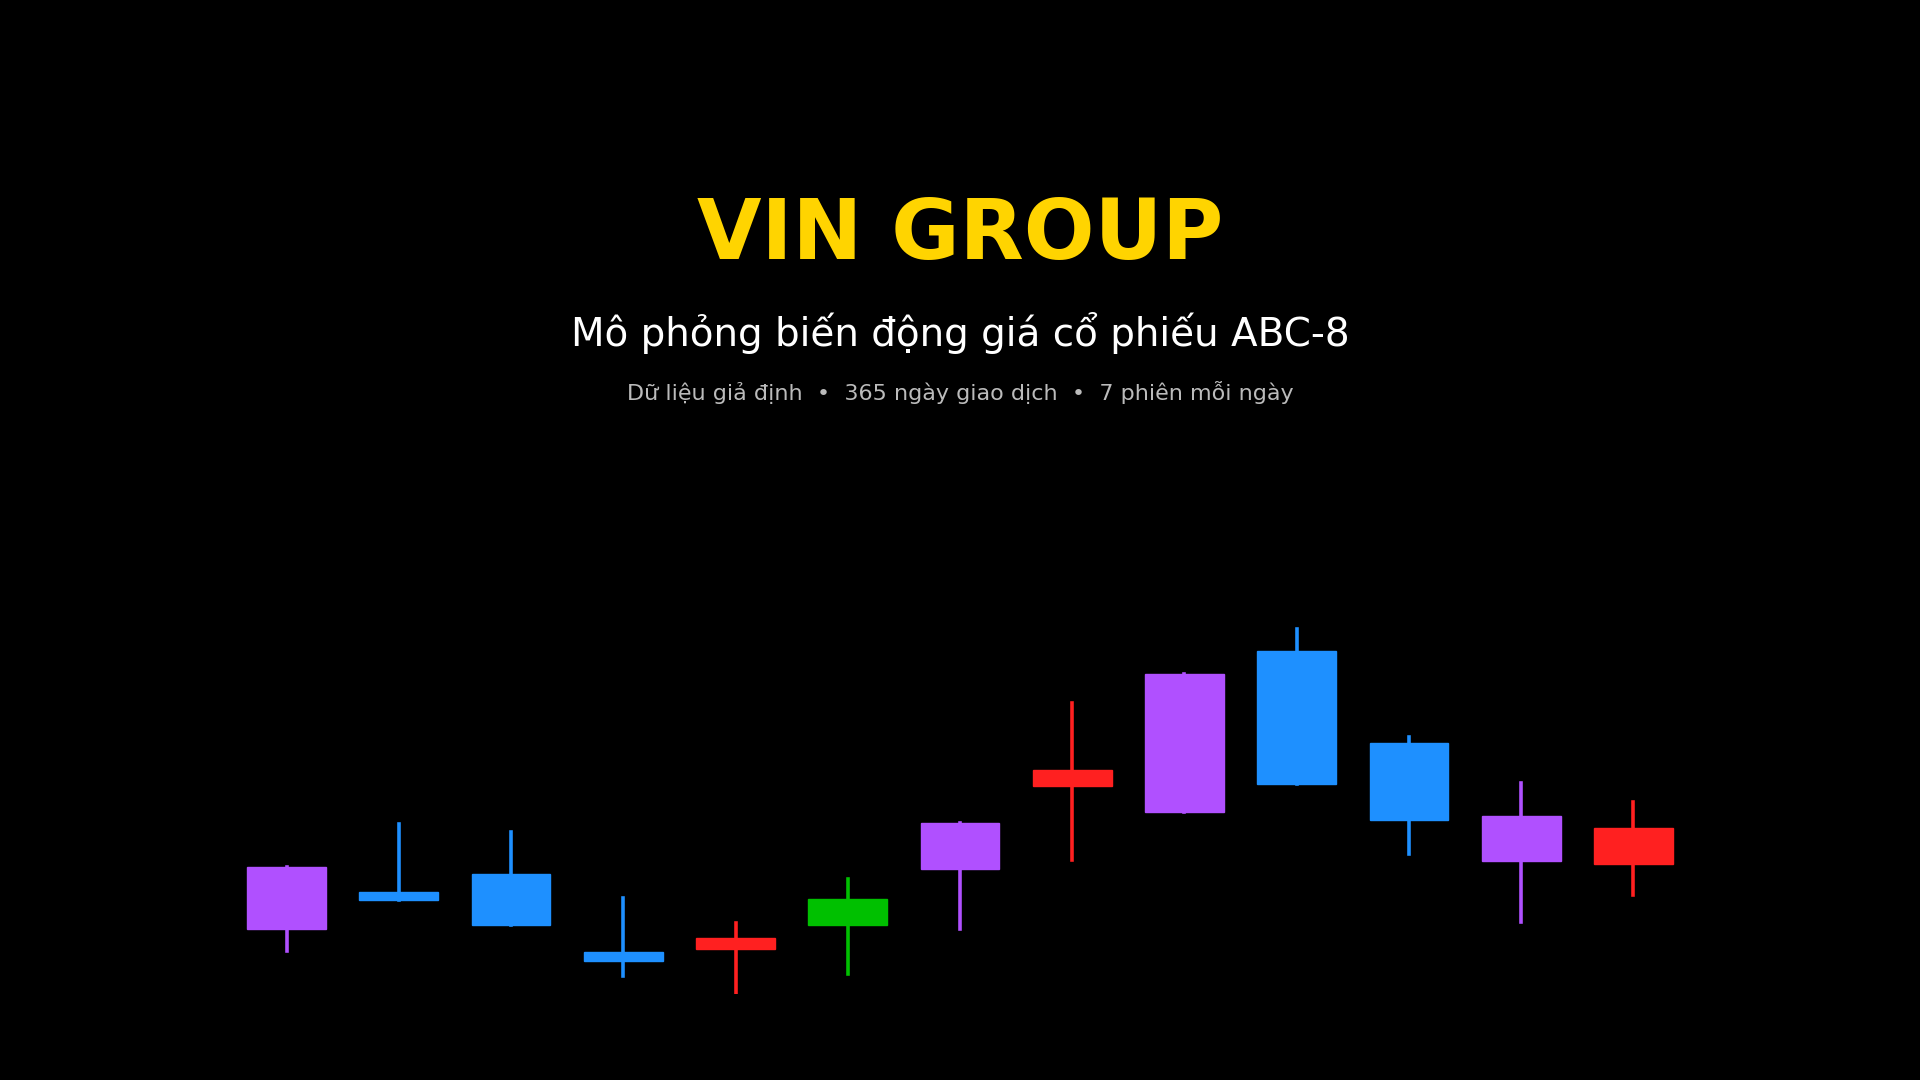

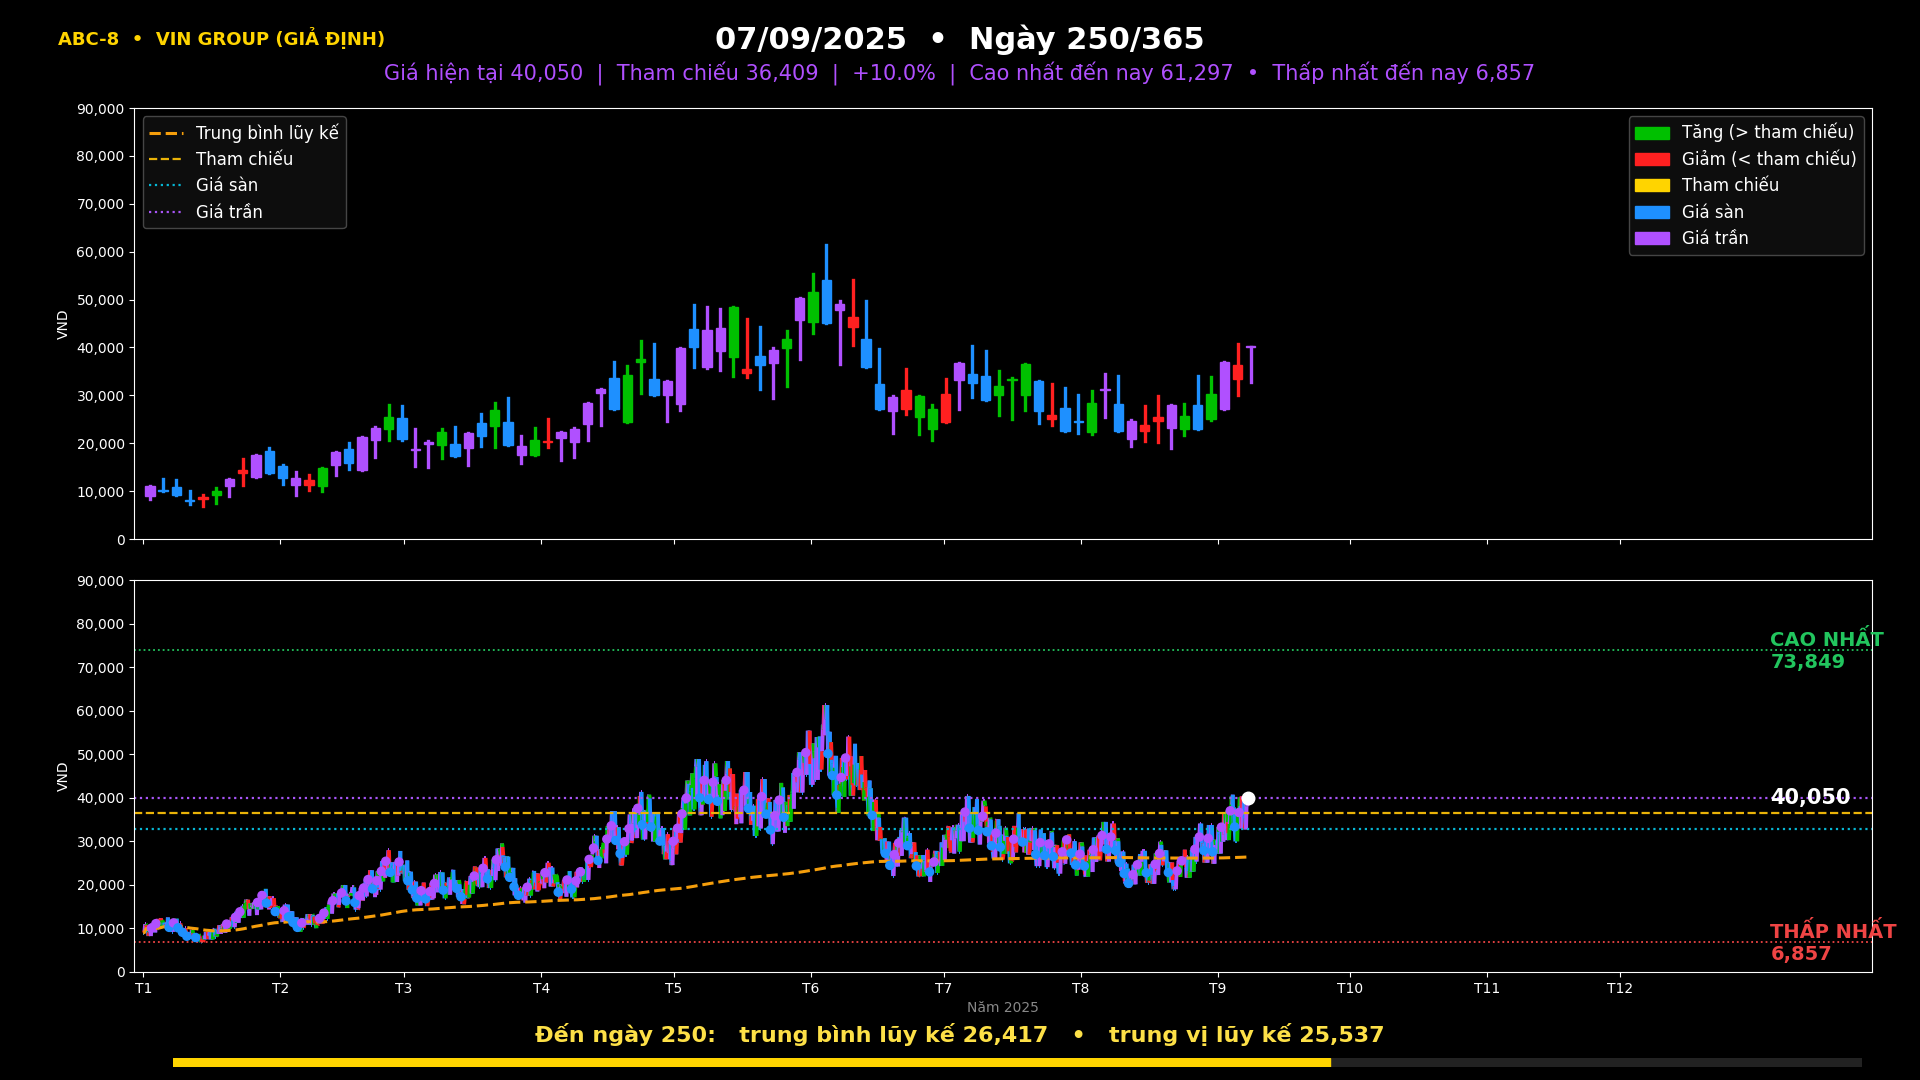

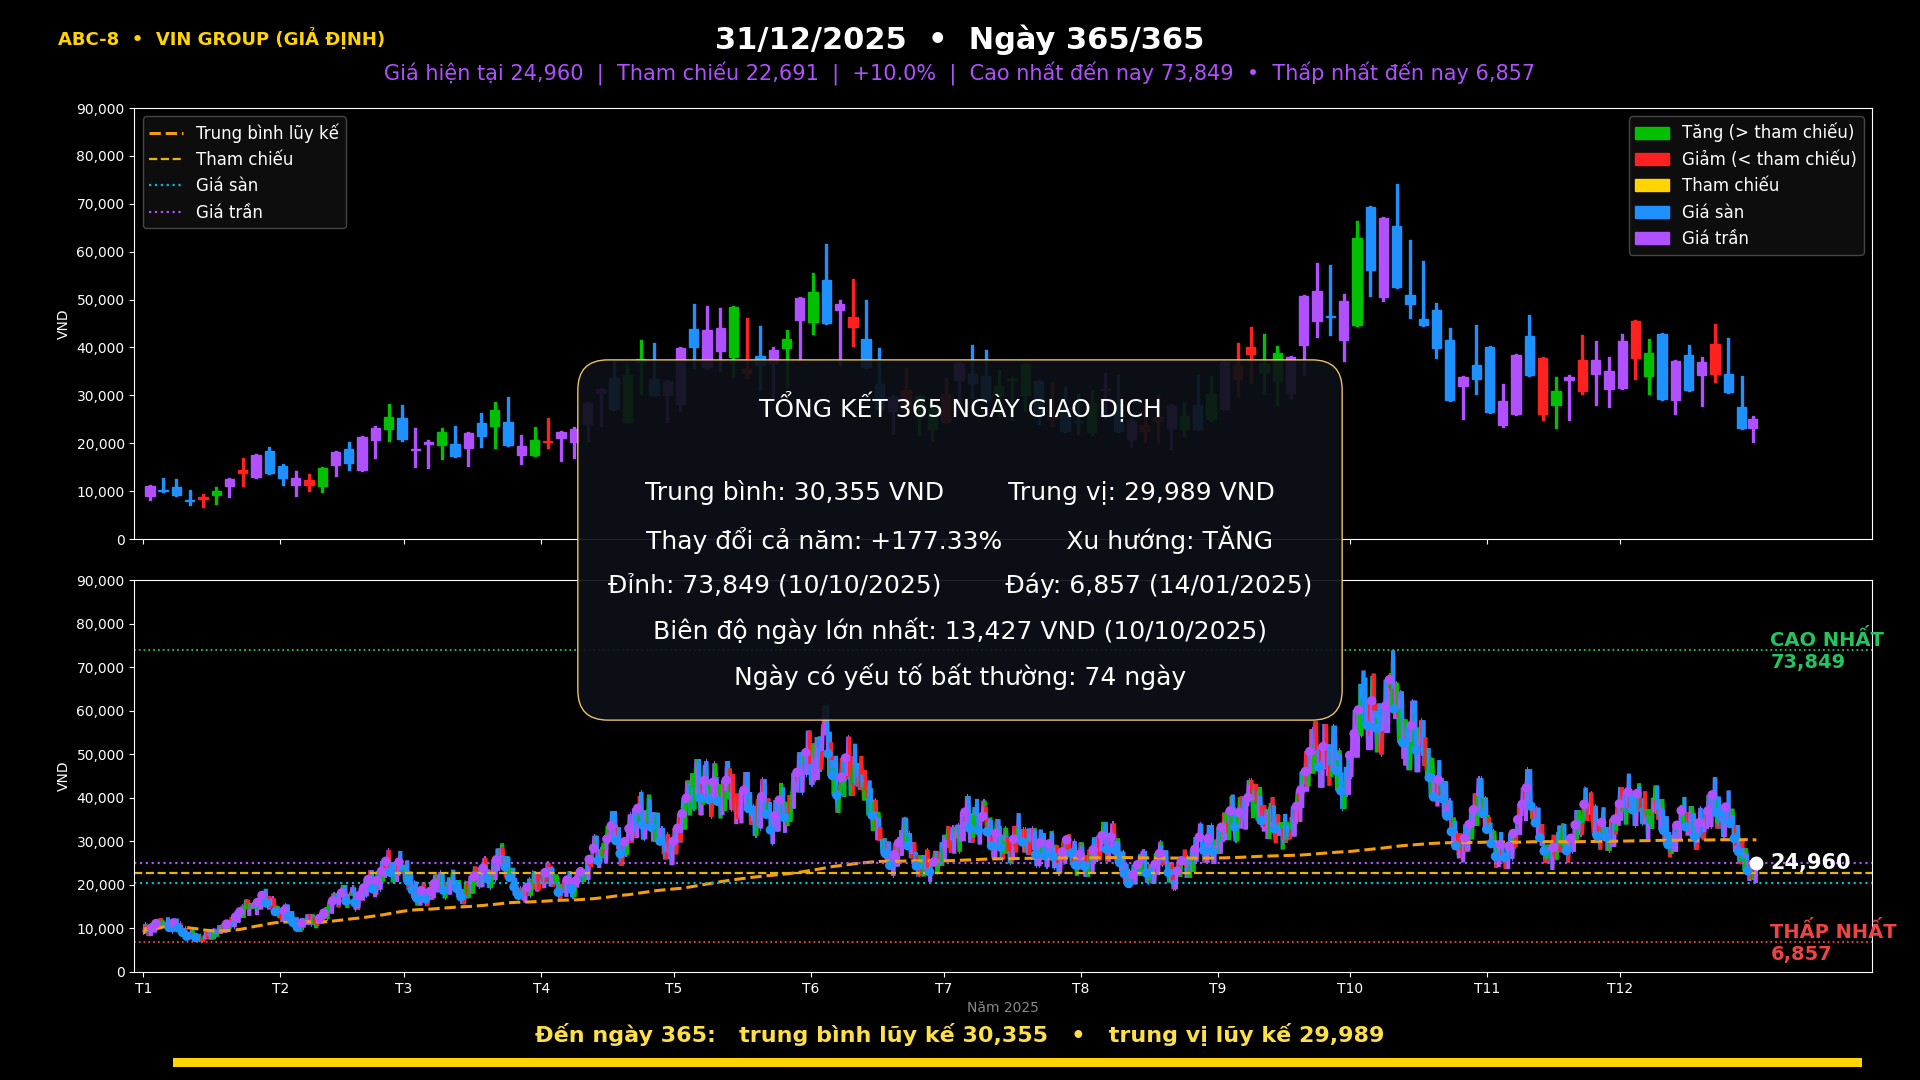

In [8]:
for item in [("intro", 1.0), ("motion", 250.0), ("outro", 1.0)]:
    display(Image(charts.save_frame(df, item, f"output/preview_{item[0]}.png"), width=900))

## 6. Xuất video 1 phút 30 giây

Ô này mất khoảng **7–10 phút** trên máy thường (1080 khung hình). File ra là `output/abc.mp4`.

Video đã lưu tại: output/abc.mp4


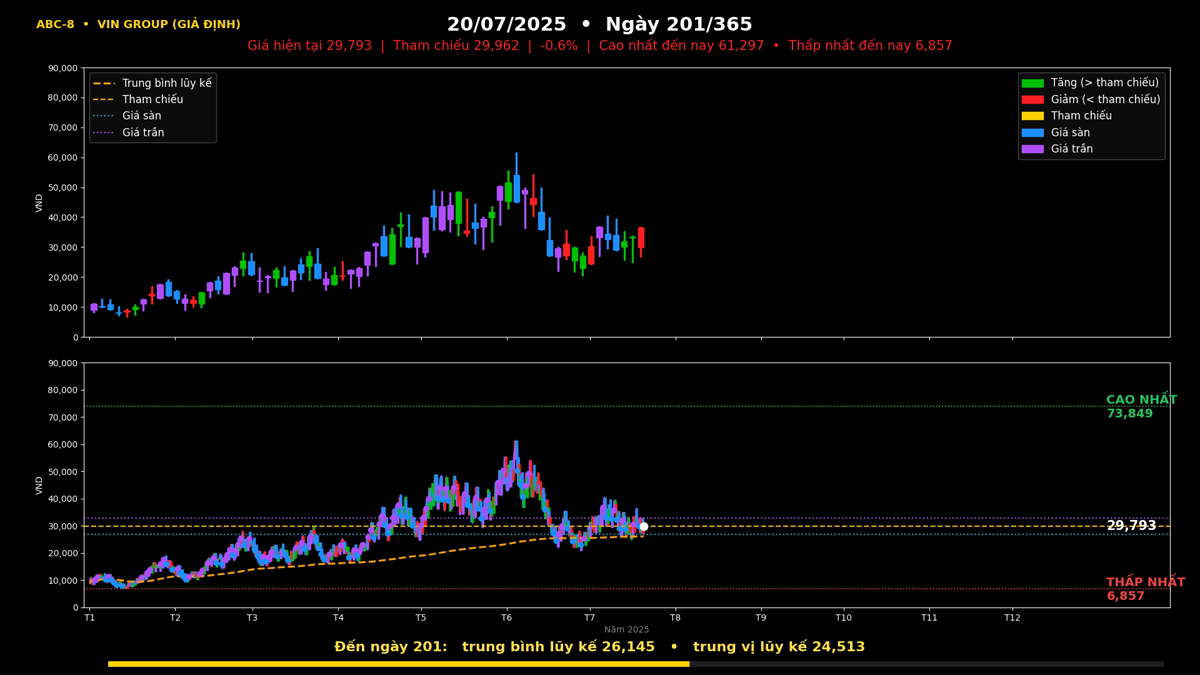

In [9]:
path = charts.build_animation(df, "output/abc.mp4")
print("Video đã lưu tại:", path)